# Multi-Retinal-Disease Detection Using Hybrid Transformer  
EfficientNet-B3 + CBAM + FPN + Swin-T -> fusion -> 8 yes/no questions (multi-label) on ODIR-5K, with full metrics, Grad-CAM/occlusion XAI and a web UI.

**Before you start (Kaggle):** Settings -> Accelerator **GPU T4 x2** (or P100), Internet **ON**. Optional: Add Input -> `ocular-disease-recognition-odir5k`.

## How the data flows 
```
Original ODIR-5K challenge data (5,000 patients)
        |  official training set: about 7,000 images (3,500 patients) + data.xlsx
        v
[Step 3] verify: folder, image count, data.xlsx, exact columns, left/right names
        v
[Step 4] match image names with data.xlsx -> left/right eye -> read keywords -> 8 labels
         -> drop unusable eyes (missing file, only image-quality keywords)
        v
Clean dataframe (one row per image, unique image names)
        v
[Step 5] split by PATIENT: 70 / 15 / 15  (verified: no patient in two sets)
        v
[Step 6] preprocessing (resize 224 + CLAHE) generated from the split dataframe
        v
[Step 7-10] train -> keep the best VALIDATION checkpoint
        v
[Step 11-15] evaluate: many metrics + curves + label-quality audit
        v
[Step 17-19] explain (Grad-CAM) + web UI
```


## Order of work -> cells
| Task | Where |
|---|---|
| 3.1 verify the dataset | Step 3 |
| 3.2 verify the patient-level split | Step 5 |
| 3.3 address overfitting | Step 2 (regularisation), Step 7 (augmentation), Step 11 (fit diagnosis) |
| 3.4 use the best validation checkpoint | Step 10 |
| 3.5 evaluate with multiple metrics | Steps 12-15 |
| 3.6 investigate label quality | Step 15c |

## Epochs
The maximum is set in the **Trial cell** (default 30). Early stopping can finish sooner. The code prints *max epochs configured / epochs run / best epoch* after training and saves them in `run_summary.json`.

## Honest expectations
- 80-85% **label-wise** accuracy is a realistic target for 8 yes/no questions, but it must be **measured**, not assumed.
- It is not comparable to 92% single-label accuracies in papers (see the checklist in the last cell).
- Overfitting and label noise cannot be removed completely; this notebook **measures** them (Step 11, Step 15c) and reduces them.
- Always report macro AUC, macro F1, precision, recall, specificity, PR-AUC, label-wise **and** exact-match accuracy.

## Step 1 - Setup
**What:** installs and imports the libraries and checks the GPU.
**How:** `timm` supplies pretrained EfficientNet-B3 and Swin-T, PyTorch trains them, scikit-learn computes metrics. `use_amp` turns on mixed precision (16-bit numbers where safe).
**Why:** a GPU is 20-50x faster than a CPU for images; mixed precision saves memory and time.

In [3]:

%pip install -q kagglehub timm

import os, glob, re, json, shutil, random, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
import timm

from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    multilabel_confusion_matrix, cohen_kappa_score,
    f1_score, average_precision_score,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Temporarily disable AMP to investigate NaN values
use_amp = False

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable GPU in Kaggle settings.")

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("Mixed precision (AMP):", use_amp)

Note: you may need to restart the kernel to use updated packages.
Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu128
timm: 1.0.29
Mixed precision (AMP): False


## Step 2 - Configuration (every setting in one dictionary `CFG`)
**What:** one place for all numbers, so every experiment is reproducible.
**Key settings and why**
- `epochs` = maximum passes over the training images. `patience` = early-stopping patience.
- `dropout`, `weight_decay`, `drop_path` = **regularisation**: they stop the model from memorising the training images (overfitting).
- `data_mode` = Option A or B. `split` = train/val/test fractions (by patient). `thr_metric` = threshold rule.
- `seed` fixes the random numbers so a run can be repeated.

**Formula (weight decay, AdamW):** `w <- w - lr * (gradient + lambda * w)`. The `lambda * w` term pulls every weight a little towards 0, so no single weight can become huge and memorise noise.

In [4]:
CFG = dict(
    data_mode="raw",
    img_size=224,
    batch_size=32,

    epochs=35,
    patience=5,
    num_workers=2,

    lr_backbone=2e-5,
    lr_head=2e-4,

    weight_decay=1e-1,
    dropout=0.6,
    drop_path=0.2,

    T_0=35,
    T_mult=1,

    split=(0.70, 0.15, 0.15),
    split_search=300,
    seed=42,

    thr_metric="f1",
    pretrained=True,
)

CLASSES = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']

CLASS_NAMES = [
    'Normal',
    'Diabetes',
    'Glaucoma',
    'Cataract',
    'AMD',
    'Hypertension',
    'Myopia',
    'Other'
]

NUM_CLASSES = len(CLASSES)

WORK = "/kaggle/working"
CACHE_DIR = f"{WORK}/cache"
OUT_DIR = f"{WORK}/results"

for d in (CACHE_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

def seed_everything(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

seed_everything(CFG["seed"])

print("Data mode:", CFG["data_mode"])
print("Max epochs:", CFG["epochs"])
print("Patience:", CFG["patience"])
print("Learning rate (backbone):", CFG["lr_backbone"])
print("Learning rate (head):", CFG["lr_head"])
print("Weight decay:", CFG["weight_decay"])
print("Dropout:", CFG["dropout"], "| Drop path:", CFG["drop_path"])
print("Scheduler T_0 / T_mult:", CFG["T_0"], "/", CFG["T_mult"])
print("Split:", CFG["split"])

Data mode: raw
Max epochs: 35
Patience: 5
Learning rate (backbone): 2e-05
Learning rate (head): 0.0002
Weight decay: 0.1
Dropout: 0.6 | Drop path: 0.2
Scheduler T_0 / T_mult: 35 / 1
Split: (0.7, 0.15, 0.15)


## Step 3 - Verify the dataset (3.1)
**What:** locates the dataset and runs a checklist: does `Training Images` exist -> how many images -> does `data.xlsx` exist -> what are its exact columns -> do left/right keyword columns map to left/right file names?
**How:** each check prints PASS / WARN / FAIL. A FAIL on a critical check stops the notebook.
**Why:** a wrong image-label pairing is silent label noise; the model would learn from wrong answers and nothing would crash.
```
Raw folder -> count images -> data.xlsx -> columns -> names match eye side? -> OK to continue
```

In [5]:
SLUG = "andrewmvd/ocular-disease-recognition-odir5k"
hits = glob.glob("/kaggle/input/**/data.xlsx", recursive=True) or glob.glob("/kaggle/input/**/full_df.csv", recursive=True)
if hits:
    src_root = "/".join(hits[0].split("/")[:4])             # /kaggle/input/<dataset-folder>
    print("Using dataset attached to this notebook:", src_root)
else:
    import kagglehub
    print("Downloading dataset from Kaggle (Internet must be ON) ...")
    src_root = kagglehub.dataset_download(SLUG)
    print("Downloaded to:", src_root)

# ---------- 3.1 VERIFY THE DATASET (decision chain) ----------
# Does 'Training Images' exist? -> how many images? -> does data.xlsx exist? -> exact columns?
# -> do left/right keywords map cleanly to left/right image filenames?
report = []
def check(name, ok, detail="", critical=False):
    report.append({"Check": name, "Result": "PASS" if ok else ("FAIL" if critical else "WARN"), "Detail": detail})
    return ok

xlsx_hits = glob.glob(f"{src_root}/**/data.xlsx", recursive=True)
tdirs     = glob.glob(f"{src_root}/**/Training Images", recursive=True)
csv_hits  = glob.glob(f"{src_root}/**/full_df.csv", recursive=True)
pdirs     = glob.glob(f"{src_root}/**/preprocessed_images", recursive=True)
RAW = CFG["data_mode"] == "raw"

if RAW:
    check("'Training Images' folder exists", bool(tdirs), tdirs[0] if tdirs else "NOT FOUND", critical=True)
    IMG_DIR = tdirs[0] if tdirs else None
    raw_files = sorted(f for f in os.listdir(IMG_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png"))) if IMG_DIR else []
    check("Original image count", len(raw_files) > 0, f"{len(raw_files)} images (the ODIR training set has about 7000)", critical=True)
    check("data.xlsx exists", bool(xlsx_hits), xlsx_hits[0] if xlsx_hits else "NOT FOUND", critical=True)
    ann = pd.read_excel(xlsx_hits[0]) if xlsx_hits else pd.DataFrame()
    print("Exact columns in data.xlsx:", ann.columns.tolist())
    need = ["ID", "Left-Fundus", "Right-Fundus", "Left-Diagnostic Keywords", "Right-Diagnostic Keywords"]
    ok_cols = check("Required columns present", all(c in ann.columns for c in need), str([c for c in need if c not in ann.columns]), critical=True)
    if ok_cols:
        L, R = ann["Left-Fundus"].astype(str), ann["Right-Fundus"].astype(str)
        check("One row per patient (ID unique)", ann["ID"].is_unique, f"{len(ann)} rows, {ann['ID'].nunique()} unique IDs")
        check("Left-Fundus names contain 'left'",   L.str.lower().str.contains("left").all(),   f"{(~L.str.lower().str.contains('left')).sum()} bad", critical=True)
        check("Right-Fundus names contain 'right'", R.str.lower().str.contains("right").all(), f"{(~R.str.lower().str.contains('right')).sum()} bad", critical=True)
        check("File name starts with the patient ID", ((L.str.split("_").str[0] == ann["ID"].astype(str)) &
                                                        (R.str.split("_").str[0] == ann["ID"].astype(str))).all())
        ref = set(L) | set(R)
        check("Every file named in data.xlsx exists", len(ref - set(raw_files)) == 0, f"{len(ref - set(raw_files))} missing (dropped in Step 4)")
        check("No image files without a data.xlsx row", len(set(raw_files) - ref) == 0, f"{len(set(raw_files) - ref)} unlabelled files (ignored)")
        check("No duplicate file names in data.xlsx", len(ref) == 2 * len(ann), f"{2 * len(ann) - len(ref)} duplicates")
else:
    check("full_df.csv exists", bool(csv_hits), csv_hits[0] if csv_hits else "NOT FOUND", critical=True)
    check("'preprocessed_images' folder exists", bool(pdirs), pdirs[0] if pdirs else "NOT FOUND", critical=True)
    IMG_DIR = pdirs[0] if pdirs else None
    check("Image count", IMG_DIR is not None and len(os.listdir(IMG_DIR)) > 0, f"{len(os.listdir(IMG_DIR)) if IMG_DIR else 0} images (Kaggle copy)", critical=True)

rep = pd.DataFrame(report); display(rep)
assert not ((rep["Result"] == "FAIL").any()), "A critical check FAILED - fix it before continuing (see table above)."
print("\nVerification finished. WARN rows are not fatal; they are handled (dropped or ignored) in Step 4.")

Using dataset attached to this notebook: /kaggle/input/datasets
Exact columns in data.xlsx: ['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords', 'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']


,Check,Result,Detail
0,'Training Images' folder exists,PASS,/kaggle/input/datasets/andrewmvd/ocular-diseas...
1,Original image count,PASS,7000 images (the ODIR training set has about 7...
2,data.xlsx exists,PASS,/kaggle/input/datasets/andrewmvd/ocular-diseas...
3,Required columns present,PASS,[]
4,One row per patient (ID unique),PASS,"3500 rows, 3500 unique IDs"
5,Left-Fundus names contain 'left',PASS,0 bad
6,Right-Fundus names contain 'right',PASS,0 bad
7,File name starts with the patient ID,PASS,
8,Every file named in data.xlsx exists,PASS,0 missing (dropped in Step 4)
9,No image files without a data.xlsx row,PASS,0 unlabelled files (ignored)



Verification finished. WARN rows are not fatal; they are handled (dropped or ignored) in Step 4.


## Step 4 - Build the clean dataframe (images -> per-eye labels)
**What:** for every patient row and each eye, read the diagnostic keywords and convert them to the 8 labels (N, D, G, C, A, H, M, O).
**How (rules):** `normal fundus` -> N; `hypertensive...` -> H; any other `...retinopathy` or `diabet...` -> D; `glaucoma` -> G (suspected glaucoma -> Other); `cataract` -> C; `macular degeneration` -> A; `myopia` -> M; anything else -> O. Image-quality keywords (lens dust, low quality ...) are ignored; an eye with *only* such keywords is dropped. If an eye is both 'normal' and diseased, the disease wins.
**Why:** each eye needs its own label; a healthy eye must not inherit the other eye's disease. The printed **data-flow table** shows exactly how many images were removed and why.
```
~7,000 original images -> missing file / unusable keywords removed -> clean images (printed above)
```
*This mapping is my best interpretation. Step 15c prints the keyword audit so you can check and edit it.*

DATA FLOW (this run)
  1. eye entries in data.xlsx                   7000
     dropped: only image-quality keywords       29
  2. clean images kept                          6971
  contradictions fixed (normal + disease -> disease): 3

Images: 6971 | Patients: 3499 | Average labels per image: 1.07


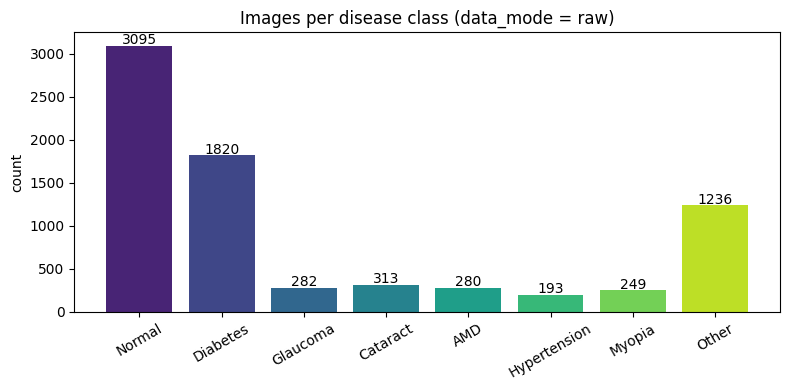

In [6]:
# ---------- Step 4: build the clean dataframe ----------
POOR = ("lens dust", "low image quality", "image offset", "optic disk photographically invisible", "anterior segment image")
SPLIT_RE = r"[,;\u3001\uff0c\uff1b]"
kw_log = Counter()                     # (keyword, assigned label) -> count, used by the label-quality audit (Step 15c)

def kw_to_labels(text):
    """One eye's keyword string -> (8 labels or None, reason, conflict_flag)."""
    lab = dict.fromkeys(CLASSES, 0)
    ks = [k.strip().lower() for k in re.split(SPLIT_RE, str(text)) if k.strip() and k.strip().lower() != "nan"]
    if not ks: return None, "no keywords", False
    for k in ks:
        if any(p in k for p in POOR): continue                                    # quality-only keyword: ignore
        if "normal fundus" in k:                                          letter = "N"
        elif "hypertensive" in k:                                         letter = "H"
        elif ("retinopathy" in k and "chorio" not in k) or "diabet" in k: letter = "D"
        elif "glaucoma" in k and "suspect" not in k:                      letter = "G"
        elif "cataract" in k:                                             letter = "C"
        elif "macular degeneration" in k:                                 letter = "A"
        elif "myopia" in k or "myopic" in k:                              letter = "M"
        else:                                                             letter = "O"
        lab[letter] = 1; kw_log[(k, letter)] += 1
    if sum(lab.values()) == 0: return None, "only image-quality keywords", False
    conflict = lab["N"] == 1 and sum(lab[c] for c in CLASSES if c != "N") > 0   # 'normal' + a disease = contradiction
    if conflict: lab["N"] = 0                                                   # the disease wins
    return lab, "ok", conflict

audit, n_conflict, rows = Counter(), 0, []
if RAW:
    for _, r in ann.iterrows():
        for side in ("Left", "Right"):
            fn = str(r[f"{side}-Fundus"]); audit["1. eye entries in data.xlsx"] += 1
            if not os.path.exists(f"{IMG_DIR}/{fn}"):
                audit["   dropped: image file missing"] += 1; continue
            lab, reason, conflict = kw_to_labels(r[f"{side}-Diagnostic Keywords"])
            if lab is None:
                audit[f"   dropped: {reason}"] += 1; continue
            n_conflict += conflict
            rows.append({"ID": r["ID"], "filename": fn, "side": side.lower(), "keywords": str(r[f"{side}-Diagnostic Keywords"]), **lab})
    df = pd.DataFrame(rows).reset_index(drop=True)
else:
    full = pd.read_csv(csv_hits[0]); audit["1. rows in full_df.csv"] = len(full)
    df = full[["ID", "filename"] + CLASSES].copy()
    keep = df["filename"].apply(lambda f: os.path.exists(f"{IMG_DIR}/{f}"))
    audit["   dropped: image file missing"] = int((~keep).sum())
    df = df[keep].reset_index(drop=True)
    df["side"] = np.where(df["filename"].str.lower().str.contains("left"), "left", "right")
    df["keywords"] = ""
audit["2. clean images kept"] = len(df)

print("DATA FLOW (this run)")
for k, v in audit.items(): print(f"  {k:<45} {v}")
print(f"  contradictions fixed (normal + disease -> disease): {n_conflict}")
assert df["filename"].is_unique, "Duplicate image names in the clean dataframe!"
assert len(df) > 0
print("\nImages:", len(df), "| Patients:", df["ID"].nunique(), "| Average labels per image:", round(df[CLASSES].sum(axis=1).mean(), 2))

counts = df[CLASSES].sum()
plt.figure(figsize=(8, 4)); ax = plt.gca()
ax.bar(CLASS_NAMES, counts.values, color=plt.cm.viridis(np.linspace(0.1, 0.9, NUM_CLASSES)))
for i, v in enumerate(counts.values): ax.text(i, v + 20, int(v), ha="center")
plt.title(f"Images per disease class (data_mode = {CFG['data_mode']})"); plt.ylabel("count"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150); plt.show()

## Step 5 - Patient-level split (3.2)
**What:** divide patients (not images) into train 70% / validation 15% / test 15%, then print the real ratios.
**How:** list unique patient IDs, shuffle, cut at 70% and 85%. We try many shuffles and keep the one whose class proportions are closest to 70/15/15, so rare diseases are spread fairly. Then the code **asserts** that no patient or image is in two sets.
**Why:** the left and right eye of one person look alike. If one eye is in train and the other in test, the model is tested on something it has effectively seen (leakage) and the score looks too good.
**Formula:** `% of set = images in set / total images x 100`. Because each patient has 1-2 images, the image ratio is close to, but not exactly, 70/15/15.
```
Unique patients -> shuffle -> 70% | 15% | 15% -> check overlap = 0 -> images follow their patient
```

In [7]:
# ---------- 3.2 PATIENT-LEVEL SPLIT + verification ----------
tr_f, va_f, te_f = CFG["split"]
pat   = df.groupby("ID")[CLASSES].sum()                         # positives per patient
pat_n = df.groupby("ID").size()
uid   = pat.index.values
M     = np.hstack([pat.values, pat_n.values[:, None]]).astype(float)   # last column = number of images
tot, target = M.sum(0), np.array([tr_f, va_f, te_f])
n_pat = len(uid); a, b = int(tr_f * n_pat), int((tr_f + va_f) * n_pat)

best = (9.0, 0, None)
for s in range(CFG["split_search"]):                            # try many shuffles, keep the most balanced one
    perm = np.random.RandomState(CFG["seed"] + s).permutation(n_pat)
    cs = np.cumsum(M[perm], axis=0)
    tr, va = cs[a - 1], cs[b - 1] - cs[a - 1]; te = tot - cs[b - 1]
    shares = np.stack([tr, va, te]) / np.maximum(tot, 1)        # share of every class (and of images) in each split
    score = np.abs(shares - target[:, None]).max()
    if score < best[0]: best = (score, s, perm)
score, split_seed, perm = best
ids = uid[perm]
train_ids, val_ids, test_ids = ids[:a], ids[a:b], ids[b:]
idx_train = np.where(df["ID"].isin(train_ids))[0]
idx_val   = np.where(df["ID"].isin(val_ids))[0]
idx_test  = np.where(df["ID"].isin(test_ids))[0]

# --- verification: no patient or image may appear in two splits ---
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids)), "PATIENT LEAKAGE!"
assert set(df.filename[idx_train]).isdisjoint(df.filename[idx_val]) and set(df.filename[idx_train]).isdisjoint(df.filename[idx_test]) \
       and set(df.filename[idx_val]).isdisjoint(df.filename[idx_test]), "IMAGE LEAKAGE!"
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df), "Some images are in no split!"
print(f"OK: no patient or image is shared between train / val / test. (split seed {CFG['seed'] + split_seed}, worst class-share deviation {score*100:.1f} points)")

split_df = pd.DataFrame({
    "Patients": [len(train_ids), len(val_ids), len(test_ids)],
    "Images":   [len(idx_train), len(idx_val), len(idx_test)]}, index=["Train", "Val", "Test"])
split_df["% patients"] = 100 * split_df["Patients"] / split_df["Patients"].sum()
split_df["% images"]   = 100 * split_df["Images"]   / split_df["Images"].sum()
split_df.loc["Total"]  = [split_df["Patients"].sum(), split_df["Images"].sum(), 100.0, 100.0]
pd.set_option("display.float_format", lambda v: f"{v:.2f}")
print("\n===== TRAIN / VAL / TEST RATIO =====")
display(split_df.round(2).astype({"Patients": int, "Images": int}))
r = split_df.loc[["Train", "Val", "Test"], "% images"]
print(f"Image ratio   Train : Val : Test = {r['Train']:.1f}% : {r['Val']:.1f}% : {r['Test']:.1f}%")
r = split_df.loc[["Train", "Val", "Test"], "% patients"]
print(f"Patient ratio Train : Val : Test = {r['Train']:.1f}% : {r['Val']:.1f}% : {r['Test']:.1f}%")

split_tbl = pd.DataFrame({"Train": df.loc[idx_train, CLASSES].sum(), "Val": df.loc[idx_val, CLASSES].sum(),
                          "Test": df.loc[idx_test, CLASSES].sum()}).T
split_tbl.columns = CLASS_NAMES
print("\nPositive images per class in each split:"); display(split_tbl.astype(int))
print("Share of each class in each split (%):"); display((100 * split_tbl / split_tbl.sum()).round(1))
for name, row in split_tbl.iterrows():
    low = [CLASS_NAMES[i] for i, v in enumerate(row.values) if v < 30 and name != "Train"]
    if low: print(f"WARNING: {name} has fewer than 30 positives for {low} -> metrics for these classes are statistically noisy.")

pd.DataFrame({"filename": df.filename, "ID": df.ID,
              "split": np.select([df.index.isin(idx_train), df.index.isin(idx_val)], ["train", "val"], "test")}
             ).to_csv(f"{WORK}/split_assignment_{CFG['data_mode']}.csv", index=False)

OK: no patient or image is shared between train / val / test. (split seed 204, worst class-share deviation 2.3 points)

===== TRAIN / VAL / TEST RATIO =====


,Patients,Images,% patients,% images
Train,2449,4877,69.99,69.96
Val,525,1047,15.00,15.02
Test,525,1047,15.00,15.02
Total,3499,6971,100.00,100.00


Image ratio   Train : Val : Test = 70.0% : 15.0% : 15.0%
Patient ratio Train : Val : Test = 70.0% : 15.0% : 15.0%

Positive images per class in each split:


,Normal,Diabetes,Glaucoma,Cataract,AMD,Hypertension,Myopia,Other
Train,2143,1288,197,223,195,136,180,874
Val,484,258,42,41,43,26,32,181
Test,468,274,43,49,42,31,37,181


Share of each class in each split (%):


,Normal,Diabetes,Glaucoma,Cataract,AMD,Hypertension,Myopia,Other
Train,69.20,70.80,69.90,71.20,69.60,70.50,72.30,70.70
Val,15.60,14.20,14.90,13.10,15.40,13.50,12.90,14.60
Test,15.10,15.10,15.20,15.70,15.00,16.10,14.90,14.60


## Step 6 - Preprocessing: resize + CLAHE (cached)
**What:** every image is resized to 224x224 and its contrast is improved with CLAHE.
**How:** convert to LAB colour, apply CLAHE to the lightness channel only. CLAHE splits the image into 8x8 tiles and equalises each tile's brightness histogram; a *clip limit* of 2.0 caps the boost so noise is not exaggerated. Results are cached so re-runs are fast.
**Why:** fundus photos are unevenly lit; local contrast makes vessels and lesions stand out. The step is run **after** the split and has no learned parameters, so no information leaks between train and test.
**Idea of the formula:** `new brightness = CDF(old brightness) x 255`, computed per tile with the histogram clipped at the clip limit.

CLAHE train:   0%|          | 0/4877 [00:00<?, ?it/s]

CLAHE val:   0%|          | 0/1047 [00:00<?, ?it/s]

CLAHE test:   0%|          | 0/1047 [00:00<?, ?it/s]

Saved cache: (6971, 224, 224, 3)


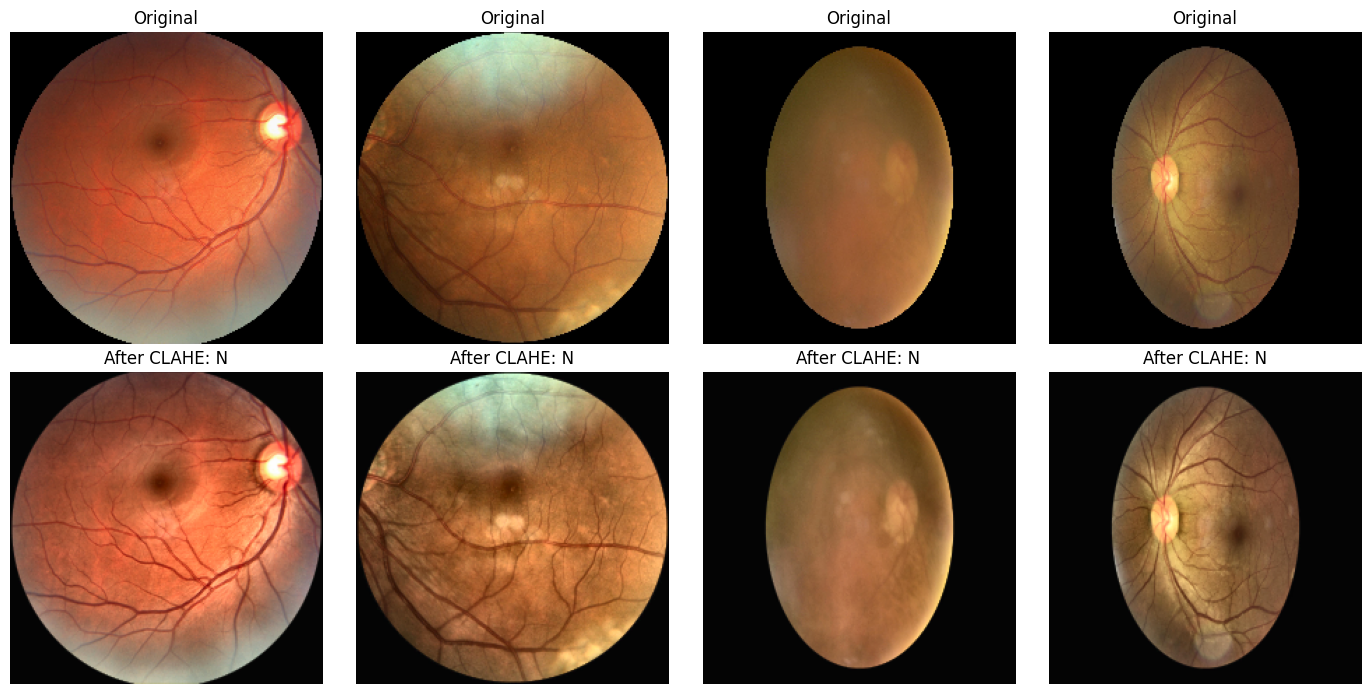

In [8]:
S = CFG["img_size"]

def clahe_preprocess(path, size=S):
    img = cv2.imread(path)
    assert img is not None, f"Cannot read {path}"
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])   # contrast only on lightness
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

names = df["filename"].values.astype(str)
cache_x = f"{CACHE_DIR}/X_{S}_{CFG['data_mode']}.npy"; cache_n = f"{CACHE_DIR}/names_{CFG['data_mode']}.npy"
if os.path.exists(cache_x) and os.path.exists(cache_n) and np.array_equal(np.load(cache_n), names):
    X = np.load(cache_x); print("Loaded cached arrays:", X.shape)
else:
    X = np.zeros((len(df), S, S, 3), dtype=np.uint8)
    for split_name, idx in (("train", idx_train), ("val", idx_val), ("test", idx_test)):   # preprocessing runs AFTER the split
        for i in tqdm(idx, desc=f"CLAHE {split_name}"): X[i] = clahe_preprocess(f"{IMG_DIR}/{names[i]}")
    np.save(cache_x, X); np.save(cache_n, names); print("Saved cache:", X.shape)
Y = df[CLASSES].values.astype(np.float32)          # labels always come from the dataframe

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(np.random.RandomState(0).choice(len(df), 4, replace=False)):
    raw = cv2.cvtColor(cv2.resize(cv2.imread(f"{IMG_DIR}/{names[i]}"), (S, S)), cv2.COLOR_BGR2RGB)
    ax[0, k].imshow(raw); ax[0, k].set_title("Original"); ax[0, k].axis("off")
    ax[1, k].imshow(X[i]); ax[1, k].set_title("After CLAHE: " + ",".join(np.array(CLASSES)[Y[i] > 0])); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/clahe_preview.png", dpi=120); plt.show()

## Step 7 - Augmentation and the weighted sampler
**What:** prepare the data that is fed to the model.
**How:** during training only, each image is randomly cropped, flipped, rotated and slightly brightened/darkened. A **weighted random sampler** shows images of rare diseases more often.
**Why:** augmentation gives the model many 'new' versions of an image, which reduces overfitting. The sampler fights class imbalance (Hypertension has about 10x fewer images than Normal).
**Formula:** `weight(image) = max over its positive classes of 1 / (number of training images of that class)`.

In [9]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0), antialias=True),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.GaussianBlur(3, sigma=(0.1, 1.5)),
])

class ODIRDataset(Dataset):
    def __init__(self, X, Y, train=False):
        self.X, self.Y, self.train = X, Y, train
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1)      # uint8, CxHxW
        if self.train: img = train_tf(img)                      # augmentation ONLY for training
        img = (img.float() / 255.0 - MEAN) / STD
        return img, torch.from_numpy(self.Y[i])

X_tr, Y_tr = X[idx_train], Y[idx_train]
X_va, Y_va = X[idx_val],   Y[idx_val]
X_te, Y_te = X[idx_test],  Y[idx_test]

# Softened Weighted Random Sampler (weight = 1 / sqrt(frequency) of the rarest positive class)
inv_freq = 1.0 / (np.maximum(Y_tr.sum(0), 1) ** 0.5)
w = (Y_tr * inv_freq).max(1)
w[Y_tr.sum(1) == 0] = inv_freq.mean()
sampler = WeightedRandomSampler(torch.from_numpy(w).double(), num_samples=len(w), replacement=True)

bs, nw = CFG["batch_size"], CFG["num_workers"]
train_loader = DataLoader(ODIRDataset(X_tr, Y_tr, True),  batch_size=bs, sampler=sampler, num_workers=nw, pin_memory=True, drop_last=True)
val_loader   = DataLoader(ODIRDataset(X_va, Y_va, False), batch_size=bs*2, shuffle=False, num_workers=nw, pin_memory=True)
test_loader  = DataLoader(ODIRDataset(X_te, Y_te, False), batch_size=bs*2, shuffle=False, num_workers=nw, pin_memory=True)

xb, yb = next(iter(train_loader))
print("Batch:", xb.shape, yb.shape, "| positives per class in this batch:", yb.sum(0).int().tolist())

Batch: torch.Size([32, 3, 224, 224]) torch.Size([32, 8]) | positives per class in this batch: [5, 12, 3, 2, 4, 1, 2, 8]


## Trial cell - change epochs here
The only place to change epochs. Run it and everything below. See the table in the first cell for the trial order.

In [10]:
TAG = "trial2"
EPOCHS = 35

CFG["epochs"] = EPOCHS
CFG["patience"] = 5
CFG["T_0"] = EPOCHS
CFG["T_mult"] = 1

OUT_DIR = f"{WORK}/results_{TAG}"
os.makedirs(OUT_DIR, exist_ok=True)

seed_everything(CFG["seed"])

print("=" * 50)
print("EXPERIMENT:", TAG)
print("Maximum epochs:", CFG["epochs"])
print("Early stopping patience:", CFG["patience"])
print("Scheduler T_0 / T_mult:", CFG["T_0"], "/", CFG["T_mult"])
print("AMP enabled:", use_amp)
print("Results directory:", OUT_DIR)
print("=" * 50)

EXPERIMENT: trial2
Maximum epochs: 35
Early stopping patience: 5
Scheduler T_0 / T_mult: 35 / 1
AMP enabled: False
Results directory: /kaggle/working/results_trial2


## Step 8 - The hybrid model
**What:** two experts look at the same image and their opinions are combined.
**How:** **EfficientNet-B3** (CNN) studies small local details. **CBAM** tells it *which feature maps* and *which places* matter: `M_c = sigmoid(MLP(avgpool(F)) + MLP(maxpool(F)))`, then `M_s = sigmoid(conv7x7([mean_c(F); max_c(F)]))`. **FPN** merges coarse and fine feature maps top-down (`P_i = Conv(C_i) + upsample(P_(i+1))`) so tiny lesions keep meaning. **Swin-T** (transformer) looks at the whole picture with attention inside shifted windows: `Attention = softmax(Q K^T / sqrt(d)) V`. The two vectors are concatenated (fusion) and a small classifier outputs 8 numbers; each goes through a sigmoid `p = 1 / (1 + e^-z)` = probability of that disease.
**Why:** CNNs are good at local texture (haemorrhages, microaneurysms); transformers are good at global layout (optic disc, macula, vessels). Sigmoid (not softmax) allows several diseases at once. Dropout and drop-path are regularisation.

In [11]:
EFF_W  = None    # Fix B: e.g. "/kaggle/input/timm-weights/effnet_b3.safetensors"
SWIN_W = None    # Fix B: e.g. "/kaggle/input/timm-weights/swin_tiny.safetensors"

class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1), nn.ReLU(inplace=True), nn.Conv2d(h, c, 1))
    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1))
        return x * torch.sigmoid(a)

class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2)
    def forward(self, x):
        m = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        return x * torch.sigmoid(self.conv(m))

class CBAM(nn.Module):                       # channel first, then spatial (sequential)
    def __init__(self, c):
        super().__init__()
        self.ca, self.sa = ChannelAttention(c), SpatialAttention()
    def forward(self, x): return self.sa(self.ca(x))

class FPN(nn.Module):
    def __init__(self, in_chs, out_ch=256):
        super().__init__()
        self.lateral = nn.ModuleList([nn.Conv2d(c, out_ch, 1) for c in in_chs])
        self.smooth  = nn.ModuleList([nn.Conv2d(out_ch, out_ch, 3, padding=1) for _ in in_chs])
    def forward(self, feats):
        lat = [l(f) for l, f in zip(self.lateral, feats)]
        for i in range(len(lat) - 1, 0, -1):                     # top-down pathway
            lat[i - 1] = lat[i - 1] + F.interpolate(lat[i], size=lat[i - 1].shape[-2:], mode="nearest")
        return [s(l) for s, l in zip(self.smooth, lat)]

class HybridNet(nn.Module):
    def __init__(self, num_classes=8, pretrained=True, dropout=0.5, drop_path=0.1, fpn_ch=256):
        super().__init__()
        self.cnn  = timm.create_model("efficientnet_b3", pretrained=pretrained, features_only=True,
                                      out_indices=(1, 2, 3, 4), drop_path_rate=drop_path,
                                      pretrained_cfg_overlay=dict(file=EFF_W) if EFF_W else None)
        chs       = self.cnn.feature_info.channels()
        self.cbam = nn.ModuleList([CBAM(c) for c in chs])
        self.fpn  = FPN(chs, fpn_ch)
        self.swin = timm.create_model("swin_tiny_patch4_window7_224", pretrained=pretrained, num_classes=0,
                                      drop_path_rate=drop_path,
                                      pretrained_cfg_overlay=dict(file=SWIN_W) if SWIN_W else None)
        fused = fpn_ch * len(chs) + self.swin.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(fused), nn.Dropout(dropout),
            nn.Linear(fused, 512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512, num_classes))
    def forward(self, x):
        feats = [cb(f) for cb, f in zip(self.cbam, self.cnn(x))]        # CNN + CBAM
        cnn_vec = torch.cat([p.mean((2, 3)) for p in self.fpn(feats)], 1)  # FPN + pooling
        swin_vec = self.swin(x)                                          # Transformer
        return self.head(torch.cat([cnn_vec, swin_vec], 1))             # fusion -> logits

model = HybridNet(NUM_CLASSES, CFG["pretrained"], CFG["dropout"], CFG["drop_path"]).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Total parameters: {n_params:.1f} M")
model.eval()
with torch.no_grad():
    print("Output shape for a dummy batch:", model(torch.randn(2, 3, S, S).to(device)).shape)

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 41.1 M
Output shape for a dummy batch: torch.Size([2, 8])


## Step 9 - Loss, optimiser, scheduler
**What:** how the model is told it is wrong, and how it learns from that.
**How:** **Asymmetric Loss**: for a present disease `L+ = -(1-p)^g+ * log(p)`; for an absent disease `L- = -(p_m)^g- * log(1 - p_m)` with `p_m = max(p - m, 0)` (here `g+ = 1, g- = 4, m = 0.05`). **AdamW** updates the weights. The **cosine schedule with warm restarts** lowers the learning rate smoothly and restarts it: `lr_t = lr_min + 0.5 (lr_max - lr_min)(1 + cos(pi * T_cur / T_i))`. `GradScaler` keeps 16-bit training stable; gradients are clipped at 1.0.
**Why:** most of the 8 yes/no answers are 'absent', so easy negatives would drown the rare positives; ASL shrinks the loss of easy negatives so the rare diseases are learned.

In [12]:

# ============================================
# STEP 9: LOSS, OPTIMIZER AND SCHEDULER
# ============================================

class AsymmetricLoss(nn.Module):
    def __init__(
        self,
        gamma_neg=4,
        gamma_pos=1,
        clip=0.05,
        eps=1e-8
    ):
        super().__init__()

        self.gn = gamma_neg
        self.gp = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, y):
        logits = logits.float()
        y = y.float()

        p = torch.sigmoid(logits)

        p_pos = p
        p_neg = (1 - p + self.clip).clamp(max=1)

        loss = (
            y * torch.log(p_pos.clamp(min=self.eps))
            + (1 - y) * torch.log(p_neg.clamp(min=self.eps))
        )

        pt = p_pos * y + p_neg * (1 - y)
        gamma = self.gp * y + self.gn * (1 - y)

        loss = loss * torch.pow(1 - pt, gamma)

        return -loss.sum() / logits.size(0)


criterion = AsymmetricLoss(
    gamma_neg=4,
    gamma_pos=1,
    clip=0.05
)

backbone_params = (
    list(model.cnn.parameters())
    + list(model.swin.parameters())
)

new_params = (
    list(model.cbam.parameters())
    + list(model.fpn.parameters())
    + list(model.head.parameters())
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": CFG["lr_backbone"]
        },
        {
            "params": new_params,
            "lr": CFG["lr_head"]
        }
    ],
    weight_decay=CFG["weight_decay"]
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=CFG["T_0"],
    T_mult=CFG["T_mult"],
    eta_min=1e-7
)

# AMP is disabled for the initial stability test
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Asymmetric Loss ready")
print("AdamW optimizer ready")
print("Cosine scheduler ready")
print("GradScaler enabled:", use_amp)

Asymmetric Loss ready
AdamW optimizer ready
Cosine scheduler ready
GradScaler enabled: False


## Step 10 - Training loop (3.4 best validation checkpoint)
**What:** repeat for each epoch: learn from all training batches, then test on the validation set.
**How:** after every epoch the macro ROC-AUC on validation is computed. If it is the best so far, the weights are saved (**best validation checkpoint**). If it does not improve for `patience` epochs, training stops (**early stopping**).
**Why:** the last epoch is usually over-trained. The checkpoint with the best validation score generalises better, and macro AUC is chosen because it does not depend on a threshold and treats every disease equally.
The cell prints **max epochs configured / epochs run / best epoch**.

In [13]:

# ============================================
# STEP 10: TRAINING + VALIDATION
# ============================================

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()

    logits_list = []
    ys = []

    for batch_idx, (x, y) in enumerate(loader):
        x = x.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            out = model(x)

            if tta:
                flipped_out = model(x.flip(3))
                out = (out + flipped_out) / 2

        out = out.float()

        if not torch.isfinite(out).all():
            raise RuntimeError(
                f"NaN/Inf in validation logits at batch {batch_idx}. "
                "Inspect the model and training weights."
            )

        logits_list.append(out.cpu())
        ys.append(y.cpu())

    logits = torch.cat(logits_list)
    ys = torch.cat(ys).float()

    probs = torch.sigmoid(logits)

    if not torch.isfinite(probs).all():
        raise RuntimeError(
            "NaN/Inf in validation probabilities."
        )

    return ys.numpy(), probs.numpy(), logits


def macro_auc(y, p):
    auc_scores = []

    for c in range(y.shape[1]):
        y_true = y[:, c]
        y_score = p[:, c]

        if not np.isfinite(y_score).all():
            raise ValueError(
                f"NaN/Inf predictions for {CLASS_NAMES[c]}. "
                "The model output is unstable."
            )

        # AUC requires positive and negative examples
        if len(np.unique(y_true)) < 2:
            print(
                f"Skipping {CLASS_NAMES[c]}: "
                "only one label in validation set."
            )
            continue

        score = roc_auc_score(y_true, y_score)
        auc_scores.append(score)

    if not auc_scores:
        raise ValueError(
            "No valid classes available for macro AUC."
        )

    return float(np.mean(auc_scores))


best_auc = -1.0
history = []

best_epoch = 0
bad = 0

BEST_PATH = f"{OUT_DIR}/best_hybrid_model.pth"

print(
    f"Training for at most {CFG['epochs']} epochs "
    f"(early-stopping patience {CFG['patience']})."
)

for epoch in range(CFG["epochs"]):

    model.train()

    t0 = time.time()
    run_loss = 0.0
    n_seen = 0

    for i, (x, y) in enumerate(
        tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{CFG['epochs']}",
            leave=False
        )
    ):

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).float()

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(x)

        if not torch.isfinite(logits).all():
            raise RuntimeError(
                f"NaN/Inf training logits at epoch "
                f"{epoch+1}, batch {i+1}."
            )

        loss = criterion(logits.float(), y)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"NaN/Inf loss at epoch "
                f"{epoch+1}, batch {i+1}."
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        grad_norm = nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        if not torch.isfinite(grad_norm):
            raise RuntimeError(
                f"NaN/Inf gradients at epoch "
                f"{epoch+1}, batch {i+1}."
            )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step(
            epoch + i / len(train_loader)
        )

        run_loss += loss.item() * x.size(0)
        n_seen += x.size(0)

    # Validation
    yv, pv, lv = predict(
        model,
        val_loader,
        tta=False
    )

    val_y = torch.from_numpy(yv).float()

    val_loss = criterion(
        lv.float(),
        val_y
    ).item()

    if not np.isfinite(val_loss):
        raise RuntimeError(
            "NaN/Inf validation loss detected."
        )

    v_auc = macro_auc(yv, pv)

    v_f1 = f1_score(
        yv,
        pv >= 0.5,
        average="macro",
        zero_division=0
    )

    epoch_train_loss = run_loss / n_seen

    history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": val_loss,
        "val_auc": v_auc,
        "val_f1": v_f1
    })

    flag = ""

    # Save the best validation macro AUC checkpoint
    if v_auc > best_auc:

        best_auc = v_auc
        best_epoch = epoch + 1
        bad = 0

        torch.save(
            model.state_dict(),
            BEST_PATH
        )

        flag = " <- best, saved"

    else:
        bad += 1

    elapsed = time.time() - t0

    print(
        f"Epoch {epoch+1:02d}/{CFG['epochs']} | "
        f"train {epoch_train_loss:.4f} | "
        f"val {val_loss:.4f} | "
        f"val AUC {v_auc:.4f} | "
        f"val F1@0.5 {v_f1:.4f} | "
        f"{elapsed:.0f}s{flag}"
    )

    # Early stopping
    if bad >= CFG["patience"]:

        print(
            f"Early stopping: validation AUC did not "
            f"improve for {CFG['patience']} epochs."
        )

        break


# Save training history
history_path = f"{OUT_DIR}/training_history.csv"

pd.DataFrame(history).to_csv(
    history_path,
    index=False
)

epochs_run = len(history)

print("\n===== EPOCH SUMMARY =====")
print(f"Trial                 : {TAG}")
print(f"Max epochs configured : {CFG['epochs']}")
print(f"Epochs actually run   : {epochs_run}")
print(f"Best epoch (saved)    : {best_epoch}")
print(f"Best validation AUC   : {best_auc:.4f}")
print(f"Best model            : {BEST_PATH}")
print(f"History               : {history_path}")

Training for at most 35 epochs (early-stopping patience 5).


Epoch 1/35:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 01/35 | train 0.5309 | val 0.4096 | val AUC 0.7662 | val F1@0.5 0.3634 | 126s <- best, saved


Epoch 2/35:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 02/35 | train 0.4519 | val 0.4247 | val AUC 0.7775 | val F1@0.5 0.3922 | 142s <- best, saved


...

Epoch 27/35 | train 0.2775 | val 0.3708 | val AUC 0.8602 | val F1@0.5 0.5223 | 132s


Epoch 28/35:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 28/35 | train 0.2719 | val 0.3755 | val AUC 0.8601 | val F1@0.5 0.5159 | 142s


Epoch 29/35:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 29/35 | train 0.2701 | val 0.3672 | val AUC 0.8572 | val F1@0.5 0.5237 | 132s
Early stopping: validation AUC did not improve for 5 epochs.

===== EPOCH SUMMARY =====
Trial                 : trial2
Max epochs configured : 35
Epochs actually run   : 29
Best epoch (saved)    : 24
Best validation AUC   : 0.8650
Best model            : /kaggle/working/results_trial2/best_hybrid_model.pth
History               : /kaggle/working/results_trial2/training_history.csv


## Step 11 - Curves and fit diagnosis (3.3)
**What:** plots the loss and validation metrics, then measures over/underfitting.
**How to read it**
| Sign | Meaning | Fix |
|---|---|---|
| train loss falls, val loss rises | **overfitting** | more dropout / weight decay / augmentation, check labels |
| train AUC much higher than val AUC (gap > 0.10) | **overfitting** | same |
| both losses high, both AUC low | **underfitting** | train longer, higher lr, less dropout |
| curves close together | good fit | keep going |
**Formula:** `gap = train AUC - validation AUC` (train AUC is measured on 2,000 training images without augmentation). The thresholds 0.05 / 0.10 are rules of thumb, not laws.

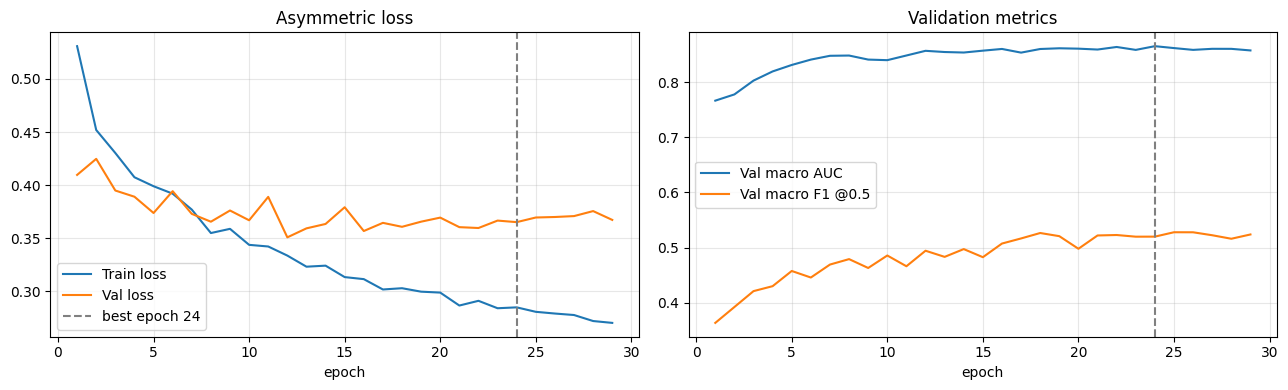

Train macro AUC 0.933 | Val macro AUC 0.865 | gap 0.068
Lowest val loss at epoch 12; at the last epoch it is +0.016 higher.
VERDICT: MILD OVERFITTING: acceptable; the best-validation checkpoint is used, so the saved model is not the over-trained one.
(Heuristic thresholds: gap > 0.10 = overfitting, 0.05-0.10 = mild. Always read it together with the curves.)


In [14]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h.epoch, h.train_loss, label="Train loss"); ax[0].plot(h.epoch, h.val_loss, label="Val loss")
ax[0].axvline(best_epoch, color="gray", ls="--", label=f"best epoch {best_epoch}")
ax[0].set_title("Asymmetric loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.epoch, h.val_auc, label="Val macro AUC"); ax[1].plot(h.epoch, h.val_f1, label="Val macro F1 @0.5")
ax[1].axvline(best_epoch, color="gray", ls="--")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

# ---------- 3.3 FIT DIAGNOSIS: overfitting or underfitting? ----------
model.load_state_dict(torch.load(BEST_PATH, map_location=device))          # best validation checkpoint
sub = np.random.RandomState(0).choice(len(X_tr), min(2000, len(X_tr)), replace=False)
tr_eval = DataLoader(ODIRDataset(X_tr[sub], Y_tr[sub], False), batch_size=bs * 2, shuffle=False, num_workers=nw)
yt, pt, _ = predict(model, tr_eval)                                         # train images, no augmentation
train_auc, val_auc_best = macro_auc(yt, pt), float(h.loc[best_epoch - 1, "val_auc"])
gap = train_auc - val_auc_best
loss_rise = float(h.val_loss.iloc[-1] - h.val_loss.min())
print(f"Train macro AUC {train_auc:.3f} | Val macro AUC {val_auc_best:.3f} | gap {gap:.3f}")
print(f"Lowest val loss at epoch {int(h.val_loss.idxmin()) + 1}; at the last epoch it is {loss_rise:+.3f} higher.")
if train_auc < 0.80 and val_auc_best < 0.80:
    verdict = "UNDERFITTING: the model cannot even fit the training data -> train longer, raise lr_backbone, lower dropout."
elif gap > 0.10:
    verdict = "OVERFITTING: train AUC is far above val AUC -> raise dropout / weight_decay / drop_path, add augmentation, check label noise (Step 15c)."
elif gap > 0.05:
    verdict = "MILD OVERFITTING: acceptable; the best-validation checkpoint is used, so the saved model is not the over-trained one."
else:
    verdict = "GOOD FIT: train and validation performance are close."
print("VERDICT:", verdict)
print("(Heuristic thresholds: gap > 0.10 = overfitting, 0.05-0.10 = mild. Always read it together with the curves.)")

## Step 12 - Best checkpoint, predictions and thresholds
**What:** turn probabilities into yes/no answers.
**How:** a disease is 'present' if `p >= t`. The default is `t = 0.5`, but rare diseases usually need a different `t`. We tune one `t` per disease **on the validation set only** with three rules, then show all of them:
- **F1 rule:** `t` that maximises F1 (balances precision and recall).
- **Youden rule:** maximises `sensitivity + specificity - 1` (balanced errors).
- **Accuracy rule:** maximises `(TP + TN) / all` (gives the highest accuracy but may miss diseases).
**Test-time augmentation (TTA):** average the model's logits for the image and its mirror image.
**Why:** this makes the accuracy-versus-recall trade-off visible. Tuning on the test set would be cheating, so it is never done.

In [15]:
# ---------- Step 12: best checkpoint -> predictions -> thresholds ----------
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
y_val, p_val, _   = predict(model, val_loader,  tta=True)
y_test, p_test, _ = predict(model, test_loader, tta=True)
y_val_i, y_test_i = y_val.astype(int), y_test.astype(int)

def confusion_counts(y, pred):
    y, pred = y.astype(int), pred.astype(int)
    tp = ((y == 1) & (pred == 1)).sum(0); fp = ((y == 0) & (pred == 1)).sum(0)
    fn = ((y == 1) & (pred == 0)).sum(0); tn = ((y == 0) & (pred == 0)).sum(0)
    return tn, fp, fn, tp

def safe_div(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return np.divide(a, b, out=np.zeros_like(a), where=b > 0)

GRID = np.arange(0.05, 0.96, 0.01)
def tune_thresholds(y, p, metric="f1"):
    """One threshold per disease, chosen on VALIDATION data only."""
    ths = []
    for c in range(y.shape[1]):
        best_t, best_s = 0.5, -1.0
        for t in GRID:
            tn, fp, fn, tp = [int(v[0]) for v in confusion_counts(y[:, [c]], p[:, [c]] >= t)]
            if   metric == "f1":     s = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
            elif metric == "youden": s = tp / max(tp + fn, 1) + tn / max(tn + fp, 1) - 1
            else:                    s = (tp + tn) / len(y)
            if s > best_s: best_t, best_s = t, s
        ths.append(best_t)
    return np.array(ths)

def headline(y, p, th):
    y = y.astype(int); pred = (p >= th).astype(int)
    tn, fp, fn, tp = confusion_counts(y, pred)
    aucs = [roc_auc_score(y[:, c], p[:, c]) for c in range(y.shape[1]) if 0 < y[:, c].sum() < len(y)]
    return {"Label-wise acc": (pred == y).mean(), "Exact-match acc": (pred == y).all(1).mean(),
            "Macro precision": safe_div(tp, tp + fp).mean(), "Macro recall": safe_div(tp, tp + fn).mean(),
            "Macro specificity": safe_div(tn, tn + fp).mean(), "Macro F1": safe_div(2 * tp, 2 * tp + fp + fn).mean(),
            "Macro AUC": float(np.mean(aucs))}

TH = {"default 0.5": np.full(NUM_CLASSES, 0.5)}
for m in ("f1", "youden", "acc"): TH[f"tuned-{m}"] = tune_thresholds(y_val_i, p_val, m)
rows = []
for name, th in TH.items():
    for split_name, (yy, pp) in {"val": (y_val_i, p_val), "test": (y_test_i, p_test)}.items():
        rows.append({"Thresholds": name, "Set": split_name, **headline(yy, pp, th)})
strategy_tbl = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("===== THRESHOLD STRATEGIES (accuracy vs recall trade-off) =====")
display(strategy_tbl)

chosen = f"tuned-{CFG['thr_metric']}"
thresholds = TH[chosen]
pred_test  = (p_test >= thresholds).astype(int)
y_true     = y_test_i
print(f"\nSelected for the final report: {chosen}")
print(pd.DataFrame({"Disease": CLASS_NAMES, "Threshold": thresholds.round(2)}).to_string(index=False))

===== THRESHOLD STRATEGIES (accuracy vs recall trade-off) =====


,Thresholds,Set,Label-wise acc,Exact-match acc,Macro precision,Macro recall,Macro specificity,Macro F1,Macro AUC
0,default 0.5,val,0.8296,0.2149,0.4230,0.7566,0.7936,0.5312,0.8668
1,default 0.5,test,0.8435,0.2283,0.4560,0.7402,0.8114,0.5488,0.8726
2,tuned-f1,val,0.8879,0.4394,0.5839,0.6520,0.8879,0.6011,0.8668
3,tuned-f1,test,0.8902,0.4470,0.5618,0.6308,0.8911,0.5845,0.8726
4,tuned-youden,val,0.8326,0.2837,0.4106,0.8250,0.8221,0.5089,0.8668
5,tuned-youden,test,0.8382,0.3056,0.4297,0.7792,0.8295,0.5184,0.8726
6,tuned-acc,val,0.9085,0.5492,0.6644,0.4517,0.9434,0.5169,0.8668
7,tuned-acc,test,0.9107,0.5645,0.6713,0.4737,0.9459,0.5316,0.8726



Selected for the final report: tuned-f1
     Disease  Threshold
      Normal     0.5600
    Diabetes     0.5400
    Glaucoma     0.5100
    Cataract     0.7900
         AMD     0.7500
Hypertension     0.5200
      Myopia     0.7500
       Other     0.5600


## Metrics: what each one tells you
For each disease, count: **TP** (disease present, predicted present), **FP** (absent, predicted present), **FN** (present, predicted absent), **TN** (absent, predicted absent).
| Metric | Formula | Plain meaning | Watch out |
|---|---|---|---|
| Precision | TP / (TP + FP) | when the model says 'disease', how often is it right | low = many false alarms |
| Recall / Sensitivity | TP / (TP + FN) | of all sick eyes, how many were found | low = missed patients (most serious in screening) |
| Specificity | TN / (TN + FP) | of all healthy eyes, how many were correctly cleared | low = many false alarms |
| F1 | 2PR / (P + R) | one number balancing precision and recall | ignores TN |
| Accuracy (per disease) | (TP + TN) / all | share of correct answers | inflated when the disease is rare |
| ROC-AUC | area under TPR vs FPR | chance that a random sick image scores higher than a random healthy one (0.5 = guessing) | can look good when negatives dominate |
| PR-AUC (Average Precision) | area under precision vs recall | ranking quality focused on positives | compare with the disease's prevalence (the 'chance' level) |
**Averages:** *macro* = plain mean over the 8 diseases (every disease counts equally, rare ones too); *micro* = pool all decisions (dominated by common diseases); *weighted* = mean weighted by number of positives.
**Label-wise accuracy** = correct yes/no answers / (images x 8). **Exact-match accuracy** = share of images where **all 8** answers are right (much stricter). **Hamming loss** = 1 - label-wise accuracy. **Cohen's kappa** = agreement beyond chance. **ODIR score** = (kappa + F1 + AUC) / 3.
**Why many metrics:** accuracy alone can be high just by answering 'absent' everywhere. Recall protects against missed disease, precision against false alarms, AUC/PR-AUC judge the ranking independent of the threshold.

## Step 13 - Full metrics on the test set
**What:** every metric above, per disease and overall, plus the headline table to report.

In [16]:
# ---------- Step 13: full metrics (test set) ----------
tn, fp, fn, tp = confusion_counts(y_true, pred_test)
support = tp + fn
mcm = multilabel_confusion_matrix(y_true, pred_test)               # (8, 2, 2) = [[TN, FP], [FN, TP]]

per_class = pd.DataFrame({
    "Prevalence":           support / len(y_true),
    "Accuracy":             (tp + tn) / len(y_true),
    "Precision":            safe_div(tp, tp + fp),
    "Recall (Sensitivity)": safe_div(tp, tp + fn),
    "Specificity":          safe_div(tn, tn + fp),
    "F1":                   safe_div(2 * tp, 2 * tp + fp + fn),
    "ROC-AUC":              [roc_auc_score(y_true[:, c], p_test[:, c]) if 0 < support[c] < len(y_true) else np.nan for c in range(NUM_CLASSES)],
    "PR-AUC":               [average_precision_score(y_true[:, c], p_test[:, c]) if support[c] > 0 else np.nan for c in range(NUM_CLASSES)],
    "Support": support, "TP": tp, "FP": fp, "FN": fn, "TN": tn}, index=CLASS_NAMES)

cols = ["Precision", "Recall (Sensitivity)", "Specificity", "F1", "ROC-AUC", "PR-AUC"]
wts = support / support.sum()
macro = per_class[cols].mean()
weighted = per_class[cols].mul(wts, axis=0).sum(min_count=1)
micro = pd.Series({"Precision": tp.sum() / (tp.sum() + fp.sum()), "Recall (Sensitivity)": tp.sum() / (tp.sum() + fn.sum()),
                   "Specificity": tn.sum() / (tn.sum() + fp.sum()), "F1": 2 * tp.sum() / (2 * tp.sum() + fp.sum() + fn.sum()),
                   "ROC-AUC": roc_auc_score(y_true.ravel(), p_test.ravel()), "PR-AUC": average_precision_score(y_true.ravel(), p_test.ravel())})
overall = pd.DataFrame({"Macro": macro, "Micro": micro, "Weighted": weighted}).T

label_acc  = float((pred_test == y_true).mean())
exact_acc  = float((pred_test == y_true).all(1).mean())
hamming    = 1 - label_acc
kappa      = cohen_kappa_score(y_true.ravel(), pred_test.ravel())
odir_score = (kappa + micro["F1"] + micro["ROC-AUC"]) / 3

print("========== PER-DISEASE METRICS (TEST SET) =========="); display(per_class)
print("\n========== OVERALL (Macro = each disease counts equally | Micro = all decisions pooled | Weighted = by support) =========="); display(overall)

headline_tbl = pd.DataFrame({"Value": {
    "Macro AUC (ROC)": macro["ROC-AUC"], "Macro PR-AUC": macro["PR-AUC"], "Macro F1": macro["F1"],
    "Macro Precision": macro["Precision"], "Macro Recall / Sensitivity": macro["Recall (Sensitivity)"],
    "Macro Specificity": macro["Specificity"], "Label-wise accuracy": label_acc, "Exact-match accuracy": exact_acc,
    "Hamming loss (1 - label-wise acc)": hamming, "Cohen's kappa": kappa, "ODIR score": odir_score}})
print("\n========== HEADLINE METRICS (report ALL of these, not only accuracy) =========="); display(headline_tbl)

per_class.to_csv(f"{OUT_DIR}/metrics_per_class.csv"); overall.to_csv(f"{OUT_DIR}/metrics_overall.csv")
headline_tbl.to_csv(f"{OUT_DIR}/metrics_headline.csv"); strategy_tbl.to_csv(f"{OUT_DIR}/threshold_strategies.csv", index=False)

========== PER-DISEASE METRICS (TEST SET) ==========


,Prevalence,Accuracy,Precision,Recall (Sensitivity),Specificity,F1,ROC-AUC,PR-AUC,Support,TP,FP,FN,TN
Normal,0.4470,0.7287,0.6369,0.9145,0.5786,0.7509,0.8281,0.7580,468,428,244,40,335
Diabetes,0.2617,0.7564,0.5274,0.6679,0.7878,0.5894,0.8077,0.6916,274,183,164,91,609
Glaucoma,0.0411,0.9341,0.3333,0.6047,0.9482,0.4298,0.9063,0.5529,43,26,52,17,952
Cataract,0.0468,0.9819,0.8261,0.7755,0.9920,0.8000,0.9828,0.8444,49,38,8,11,990
AMD,0.0401,0.9647,0.5676,0.5000,0.9841,0.5316,0.9255,0.5008,42,21,16,21,989
Hypertension,0.0296,0.9436,0.1818,0.2581,0.9646,0.2133,0.7737,0.2103,31,8,36,23,980
Myopia,0.0353,0.9895,0.9333,0.7568,0.9980,0.8358,0.9906,0.9040,37,28,2,9,1008
Other,0.1729,0.8223,0.4882,0.5691,0.8753,0.5255,0.7662,0.5127,181,103,108,78,758



========== OVERALL (Macro = each disease counts equally | Micro = all decisions pooled | Weighted = by support) ==========


,Precision,Recall (Sensitivity),Specificity,F1,ROC-AUC,PR-AUC
Macro,0.5618,0.6308,0.8911,0.5845,0.8726,0.6218
Micro,0.5700,0.7422,0.9131,0.6448,0.9214,0.6834
Weighted,0.5776,0.7422,0.7490,0.6449,0.8304,0.6784



========== HEADLINE METRICS (report ALL of these, not only accuracy) ==========


,Value
Macro AUC (ROC),0.8726
Macro PR-AUC,0.6218
Macro F1,0.5845
Macro Precision,0.5618
Macro Recall / Sensitivity,0.6308
Macro Specificity,0.8911
Label-wise accuracy,0.8902
Exact-match accuracy,0.4470
Hamming loss (1 - label-wise acc),0.1098
Cohen's kappa,0.5811


## Step 13b - How certain are the numbers? (confidence intervals)
**What:** a 95% interval for the main metrics.
**How:** resample the test **patients** with replacement 300 times, recompute the metrics each time, and take the 2.5th and 97.5th percentiles.
**Why:** the test set is small and some diseases have about 20 positives, so a single number can be lucky. Papers should report the uncertainty.

In [17]:
# ---------- Step 13b: how certain are these numbers? (patient-level bootstrap, 95% interval) ----------
rng = np.random.RandomState(0)
test_pat = df.loc[idx_test, "ID"].values
groups = list(pd.Series(np.arange(len(test_pat))).groupby(test_pat).apply(list).values)
vals = {k: [] for k in ("Macro AUC", "Macro F1", "Label-wise acc", "Exact-match acc")}
for _ in range(300):
    pick = rng.randint(0, len(groups), len(groups))
    ii = np.concatenate([groups[k] for k in pick])
    hh = headline(y_true[ii], p_test[ii], thresholds)
    for k in vals: vals[k].append(hh[k])
ci = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in vals.items()},
                  index=["mean", "2.5%", "97.5%"]).T
print("Test-set metrics with 95% bootstrap interval (resampling PATIENTS, 300 times):"); display(ci)
ci.to_csv(f"{OUT_DIR}/metrics_confidence_intervals.csv")

Test-set metrics with 95% bootstrap interval (resampling PATIENTS, 300 times):


,mean,2.5%,97.5%
Macro AUC,0.8727,0.8538,0.8892
Macro F1,0.5808,0.5393,0.6212
Label-wise acc,0.8903,0.8825,0.8979
Exact-match acc,0.4483,0.4128,0.4845


## Step 14 - Confusion matrices
**What:** for every disease, a 2x2 table `[[TN, FP], [FN, TP]]`, plus one pooled table.
**Why:** it shows the *kind* of mistakes (false alarms vs missed disease) that a single score hides.

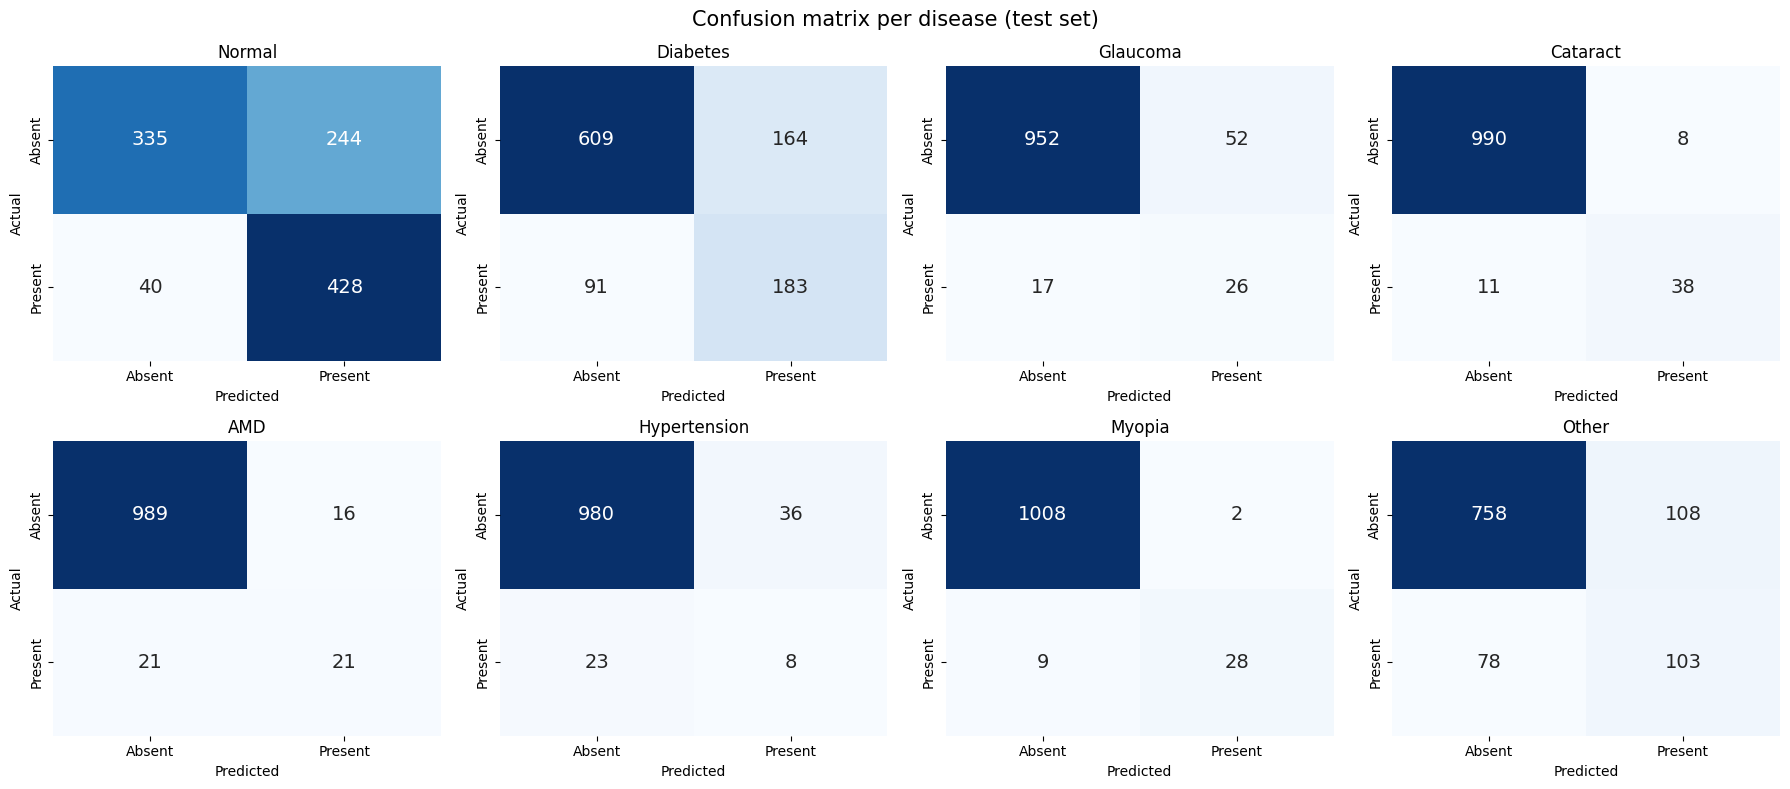

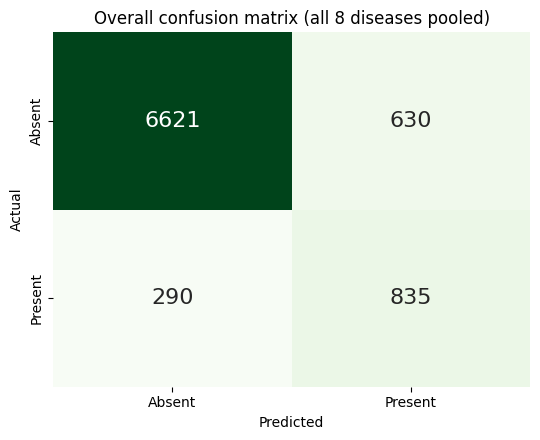

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for c, ax in enumerate(axes.ravel()):
    sns.heatmap(mcm[c], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Absent", "Present"], yticklabels=["Absent", "Present"], annot_kws={"size": 14})
    ax.set_title(CLASS_NAMES[c]); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrix per disease (test set)", fontsize=15); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrices_per_class.png", dpi=150); plt.show()

tot_m = mcm.sum(0)                                                  # all diseases pooled
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(tot_m, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Absent", "Present"], yticklabels=["Absent", "Present"], annot_kws={"size": 16})
plt.title("Overall confusion matrix (all 8 diseases pooled)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_overall.png", dpi=150); plt.show()

## Step 15 - ROC and Precision-Recall curves
**What:** curves that show performance at **every** threshold.
**How:** ROC plots TPR (recall) against FPR (1 - specificity); AUC is the area. PR plots precision against recall; PR-AUC (average precision) is `sum (R_n - R_(n-1)) * P_n`.
**Why:** ROC-AUC is threshold-free. For rare diseases the PR curve is more honest, because its 'chance' level equals the disease prevalence (shown in the legend).

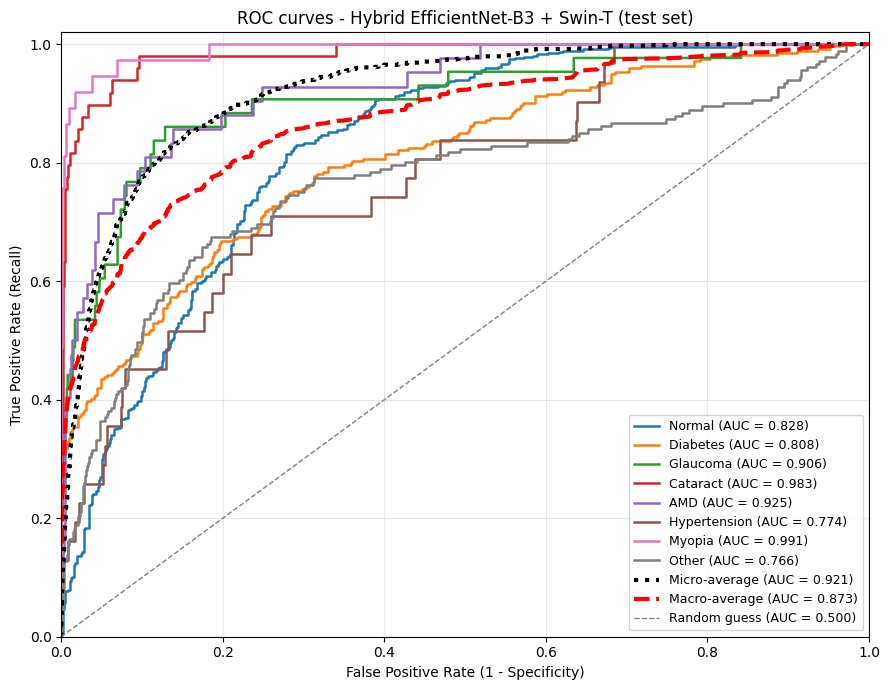

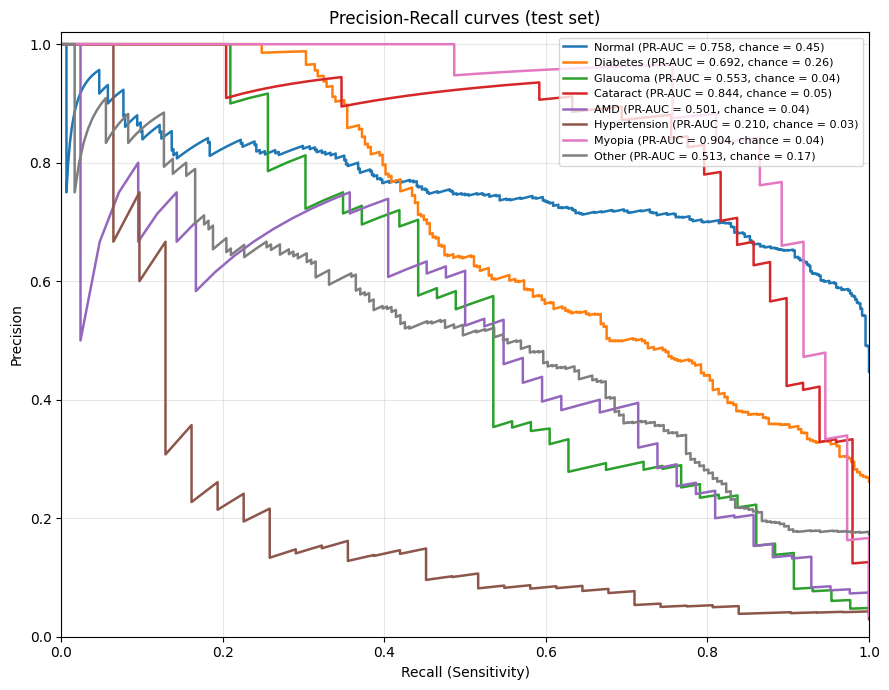

In [19]:
fpr, tpr, roc_auc = {}, {}, {}
for c in range(NUM_CLASSES):
    fpr[c], tpr[c], _ = roc_curve(y_true[:, c], p_test[:, c]); roc_auc[c] = auc(fpr[c], tpr[c])
fpr["micro"], tpr["micro"], _ = roc_curve(y_true.ravel(), p_test.ravel()); roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
all_fpr = np.unique(np.concatenate([fpr[c] for c in range(NUM_CLASSES)]))
mean_tpr = np.mean([np.interp(all_fpr, fpr[c], tpr[c]) for c in range(NUM_CLASSES)], axis=0)
fpr["macro"], tpr["macro"] = all_fpr, mean_tpr; roc_auc["macro"] = auc(all_fpr, mean_tpr)

colors = plt.cm.tab10(np.linspace(0, 1, 10))
plt.figure(figsize=(9, 7))
for c in range(NUM_CLASSES):
    plt.plot(fpr[c], tpr[c], color=colors[c], lw=1.8, label=f"{CLASS_NAMES[c]} (AUC = {roc_auc[c]:.3f})")
plt.plot(fpr["micro"], tpr["micro"], "k:", lw=3, label=f"Micro-average (AUC = {roc_auc['micro']:.3f})")
plt.plot(fpr["macro"], tpr["macro"], "r--", lw=3, label=f"Macro-average (AUC = {roc_auc['macro']:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="--", label="Random guess (AUC = 0.500)")
plt.xlim(0, 1); plt.ylim(0, 1.02); plt.xlabel("False Positive Rate (1 - Specificity)"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves - Hybrid EfficientNet-B3 + Swin-T (test set)"); plt.legend(loc="lower right", fontsize=9); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/roc_curves.png", dpi=150); plt.show()

plt.figure(figsize=(9, 7))                                           # Precision-Recall curves (PR-AUC)
for c in range(NUM_CLASSES):
    pr_, rc_, _ = precision_recall_curve(y_true[:, c], p_test[:, c])
    plt.plot(rc_, pr_, color=colors[c], lw=1.8,
             label=f"{CLASS_NAMES[c]} (PR-AUC = {per_class.iloc[c]['PR-AUC']:.3f}, chance = {per_class.iloc[c]['Prevalence']:.2f})")
plt.xlim(0, 1); plt.ylim(0, 1.02); plt.xlabel("Recall (Sensitivity)"); plt.ylabel("Precision")
plt.title("Precision-Recall curves (test set)"); plt.legend(loc="upper right", fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pr_curves.png", dpi=150); plt.show()

## Step 15c - Label-quality investigation (3.6)
**What:** hunts for label noise instead of assuming there is none.
**How:** (1) how many patients have different labels in their two eyes, (2) contradictions/empty labels, (3) a keyword -> label audit, (4) a list of images where the model strongly disagrees with the label.
**Why:** wrong labels cap the accuracy no matter how good the model is, and they look like overfitting. List (4) is saved as `label_review_list.csv`; checking about 20 of those images by eye tells you how clean the labels really are. **Noise cannot be proven to be zero; it can be measured and reduced.**

In [20]:
# ---------- 3.6 LABEL-QUALITY INVESTIGATION ----------
print("1) Do the two eyes of one patient have DIFFERENT labels?  (patient-level labels would force them to be equal = noise)")
two = df.groupby("ID").filter(lambda d: len(d) == 2)
if CFG["data_mode"] == "raw" and len(two):
    differ = two.groupby("ID")[CLASSES].nunique().gt(1).any(axis=1)
    print(f"   {differ.sum()} of {differ.size} patients with both eyes ({100 * differ.mean():.1f}%) have different labels in the two eyes.")
else:
    print("   Only measurable with data_mode='raw' (the Kaggle copy stores one label set per patient).")

print("\n2) Contradictions and empty labels")
print("   'Normal' together with a disease :", int(((df.N == 1) & (df[CLASSES[1:]].sum(axis=1) > 0)).sum()))
print("   Images with no label at all      :", int((df[CLASSES].sum(axis=1) == 0).sum()))

if kw_log:
    kwdf = pd.DataFrame([(k, l, n) for (k, l), n in kw_log.items()], columns=["keyword", "label", "count"]).sort_values("count", ascending=False)
    print("\n3) KEYWORD -> LABEL audit (top 40). Read it once: does every keyword sit in the right class?"); display(kwdf.head(40))
    print("   What ended up in 'Other' (O):"); display(kwdf[kwdf.label == "O"].head(25))

print("\n4) Images where the model STRONGLY disagrees with the label (val + test) - look at these by eye")
p_all = np.vstack([p_val, p_test]); y_all = np.vstack([y_val_i, y_test_i]); idx_all = np.concatenate([idx_val, idx_test])
dis = np.abs(y_all - p_all).max(1); order = np.argsort(-dis)[:30]
review = pd.DataFrame({
    "filename": df.filename.values[idx_all[order]],
    "label": [",".join(np.array(CLASSES)[y_all[i] > 0]) for i in order],
    "model_top": [CLASSES[int(np.argmax(p_all[i]))] + f" ({p_all[i].max():.2f})" for i in order],
    "disagreement": dis[order].round(2)})
display(review.head(15)); review.to_csv(f"{OUT_DIR}/label_review_list.csv", index=False)
print("Saved label_review_list.csv. Open ~20 of these images: if many labels look wrong, fix the keyword mapping in Step 4.")

1) Do the two eyes of one patient have DIFFERENT labels?  (patient-level labels would force them to be equal = noise)
   1237 of 3472 patients with both eyes (35.6%) have different labels in the two eyes.

2) Contradictions and empty labels
   'Normal' together with a disease : 0
   Images with no label at all      : 0

3) KEYWORD -> LABEL audit (top 40). Read it once: does every keyword sit in the right class?


,keyword,label,count
1,normal fundus,N,3100
3,moderate non proliferative retinopathy,D,997
6,mild nonproliferative retinopathy,D,552
0,cataract,C,313
18,glaucoma,G,282
12,pathological myopia,M,246
22,dry age-related macular degeneration,A,228
5,macular epiretinal membrane,O,201
10,hypertensive retinopathy,H,193
7,epiretinal membrane,O,187


   What ended up in 'Other' (O):


,keyword,label,count
5,macular epiretinal membrane,O,201
7,epiretinal membrane,O,187
8,drusen,O,180
13,myelinated nerve fibers,O,99
2,laser spot,O,95
9,vitreous degeneration,O,72
40,refractive media opacity,O,63
34,suspected glaucoma,O,44
19,spotted membranous change,O,30
44,tessellated fundus,O,29



4) Images where the model STRONGLY disagrees with the label (val + test) - look at these by eye


,filename,label,model_top,disagreement
0,136_right.jpg,O,C (0.99),0.9900
1,218_left.jpg,O,C (0.98),0.9800
2,1571_right.jpg,O,M (0.98),0.9800
3,1884_left.jpg,O,C (0.96),0.9600
4,861_left.jpg,H,D (0.95),0.9500
5,436_right.jpg,"D,O",A (0.94),0.9400
6,1674_right.jpg,O,C (0.94),0.9400
7,1626_right.jpg,O,M (0.94),0.9400
8,3138_left.jpg,N,G (0.94),0.9400
9,3029_left.jpg,N,C (0.93),0.9300


Saved label_review_list.csv. Open ~20 of these images: if many labels look wrong, fix the keyword mapping in Step 4.


## Step 16 - Save everything + setup for your paper
**What:** saves predictions, metrics and a `run_summary.json` with the full experimental setup (dataset, split ratio, epochs, preprocessing, thresholds, results).
**Why:** reviewers ask exactly these questions; the printed block is ready to paste into the Methods section.

In [21]:
pred_df = pd.DataFrame(p_test, columns=[f"prob_{n}" for n in CLASS_NAMES])
for c, n in enumerate(CLASS_NAMES):
    pred_df[f"true_{n}"] = y_true[:, c]; pred_df[f"pred_{n}"] = pred_test[:, c]
pred_df.insert(0, "filename", df.loc[idx_test, "filename"].values)
pred_df.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

# ---------- experimental setup + results (copy into your paper) ----------
setup = {
    "dataset": "ODIR-5K (Kaggle: andrewmvd/ocular-disease-recognition-odir5k)",
    "data_mode": CFG["data_mode"] + (" (original training images + data.xlsx, per-eye labels)" if RAW else " (Kaggle preprocessed copy, full_df.csv)"),
    "images_used": int(len(df)), "patients_used": int(df["ID"].nunique()),
    "split_level": "patient-level (no patient in two sets)",
    "split_ratio_images_%": {k: round(float(split_df.loc[k, "% images"]), 2) for k in ("Train", "Val", "Test")},
    "split_ratio_patients_%": {k: round(float(split_df.loc[k, "% patients"]), 2) for k in ("Train", "Val", "Test")},
    "split_counts_images": {k: int(split_df.loc[k, "Images"]) for k in ("Train", "Val", "Test")},
    "task": "multi-label, 8 diseases, one yes/no decision per disease",
    "preprocessing": f"resize {S}x{S}, CLAHE (clip 2.0, 8x8 tiles) on LAB lightness, ImageNet normalisation",
    "augmentation": "random resized crop, flips, rotation 20, brightness/contrast jitter (train only)",
    "loss": "Asymmetric loss (gamma- 4, gamma+ 1, clip 0.05)",
    "optimizer": f"AdamW (lr backbone {CFG['lr_backbone']}, head {CFG['lr_head']}, weight decay {CFG['weight_decay']}), cosine warm restarts",
    "regularisation": f"dropout {CFG['dropout']}, drop-path {CFG['drop_path']}, early stopping patience {CFG['patience']}",
    "epochs_max": CFG["epochs"], "epochs_run": int(epochs_run), "best_epoch": int(best_epoch),
    "checkpoint": "best validation macro ROC-AUC",
    "thresholds": f"per-disease, tuned on validation only ({chosen}), test-time flip augmentation",
    "test_images": int(len(idx_test)),
    "results": {k: round(float(v), 4) for k, v in headline_tbl["Value"].items()},
    "train_val_auc_gap": round(float(gap), 3)}
json.dump(setup, open(f"{OUT_DIR}/run_summary.json", "w"), indent=2)
print("========== SETUP + RESULTS FOR YOUR PAPER ==========")
print(json.dumps(setup, indent=2))

print("\nSaved files:")
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        p = os.path.join(root, f); print(f"  {p}  ({os.path.getsize(p)/1e6:.1f} MB)")

========== SETUP + RESULTS FOR YOUR PAPER ==========
{
  "dataset": "ODIR-5K (Kaggle: andrewmvd/ocular-disease-recognition-odir5k)",
  "data_mode": "raw (original training images + data.xlsx, per-eye labels)",
  "images_used": 6971,
  "patients_used": 3499,
  "split_level": "patient-level (no patient in two sets)",
  "split_ratio_images_%": {
    "Train": 69.96,
    "Val": 15.02,
    "Test": 15.02
  },
  "split_ratio_patients_%": {
    "Train": 69.99,
    "Val": 15.0,
    "Test": 15.0
  },
  "split_counts_images": {
    "Train": 4877,
    "Val": 1047,
    "Test": 1047
  },
  "task": "multi-label, 8 diseases, one yes/no decision per disease",
  "preprocessing": "resize 224x224, CLAHE (clip 2.0, 8x8 tiles) on LAB lightness, ImageNet normalisation",
  "augmentation": "random resized crop, flips, rotation 20, brightness/contrast jitter (train only)",
  "loss": "Asymmetric loss (gamma- 4, gamma+ 1, clip 0.05)",
  "optimizer": "AdamW (lr backbone 2e-05, head 0.0002, weight decay 0.1), cosine

## Step 17 - Explainable AI: Grad-CAM + occlusion
**What:** shows *where* the model looks.
**How:** **Grad-CAM** weights each feature map of the last CNN stage by the gradient of the chosen disease score: `cam = ReLU(sum_k a_k * A_k)`, `a_k` = average gradient of map `A_k`. **Occlusion** hides square patches one by one and measures the drop in probability, so it explains the whole model, including Swin-T.
**Why:** trust and debugging. If the heatmap sits on borders instead of the optic disc, macula or lesions, the model is using shortcuts.

In [22]:
# ===== Step 17: Explainable AI - Grad-CAM + occlusion sensitivity =====
# Needs: model (Step 8), CFG/device/use_amp (Steps 1-2). Works on any 224x224 CLAHE image.
S = CFG["img_size"]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class GradCAM:
    """Grad-CAM on the last EfficientNet stage (after CBAM). Gradients flow back from the chosen disease output."""
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_acts)
    def _save_acts(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, c):
        self.model.eval(); self.model.zero_grad(set_to_none=True); self.grads = None
        with torch.enable_grad():
            logits = self.model(x)
            logits[0, c].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)                 # importance of each feature map
        cam = F.relu((w * self.acts).sum(1))[0].detach().cpu().numpy()
        self.acts = None
        cam = cv2.resize(cam, (S, S))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

gradcam = GradCAM(model, model.cbam[-1])

@torch.no_grad()
def occlusion_map(x, c, patch=32, stride=16, batch=64):
    """Hide square patches one by one; the bigger the drop in probability, the more that region mattered (whole model)."""
    model.eval()
    base = torch.sigmoid(model(x))[0, c].item()
    coords = [(i, j) for i in range(0, S - patch + 1, stride) for j in range(0, S - patch + 1, stride)]
    heat, cnt = np.zeros((S, S)), np.zeros((S, S))
    for k in range(0, len(coords), batch):
        chunk = coords[k:k + batch]
        xs = x.repeat(len(chunk), 1, 1, 1)
        for n, (i, j) in enumerate(chunk):
            xs[n, :, i:i + patch, j:j + patch] = 0.0                  # 0 = mean colour after normalisation
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            p = torch.sigmoid(model(xs).float())[:, c].cpu().numpy()
        for n, (i, j) in enumerate(chunk):
            heat[i:i + patch, j:j + patch] += base - p[n]; cnt[i:i + patch, j:j + patch] += 1
    heat = np.clip(heat / np.maximum(cnt, 1), 0, None)
    return heat / (heat.max() + 1e-8)

def to_tensor(img_uint8):
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1).float() / 255.0
    return ((t - MEAN) / STD).unsqueeze(0).to(device)

def overlay(img_rgb, cam, alpha=0.45):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[..., ::-1]
    return np.uint8((1 - alpha) * img_rgb + alpha * heat)

def explain(img_uint8, c=None, occlusion=True):
    """img_uint8: 224x224x3 RGB (already CLAHE). Returns probs, disease index, Grad-CAM, occlusion map."""
    x = to_tensor(img_uint8)
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(x))[0].cpu().numpy()
    if c is None: c = int(np.argmax(probs))
    cam = gradcam(x, c)
    occ = occlusion_map(x, c) if occlusion else None
    return probs, c, cam, occ
print("XAI ready: Grad-CAM + occlusion")

XAI ready: Grad-CAM + occlusion


## Step 17b - Explanation gallery on test images
**How to read:** red = most important. Heatmaps show what the model used, not clinical proof.

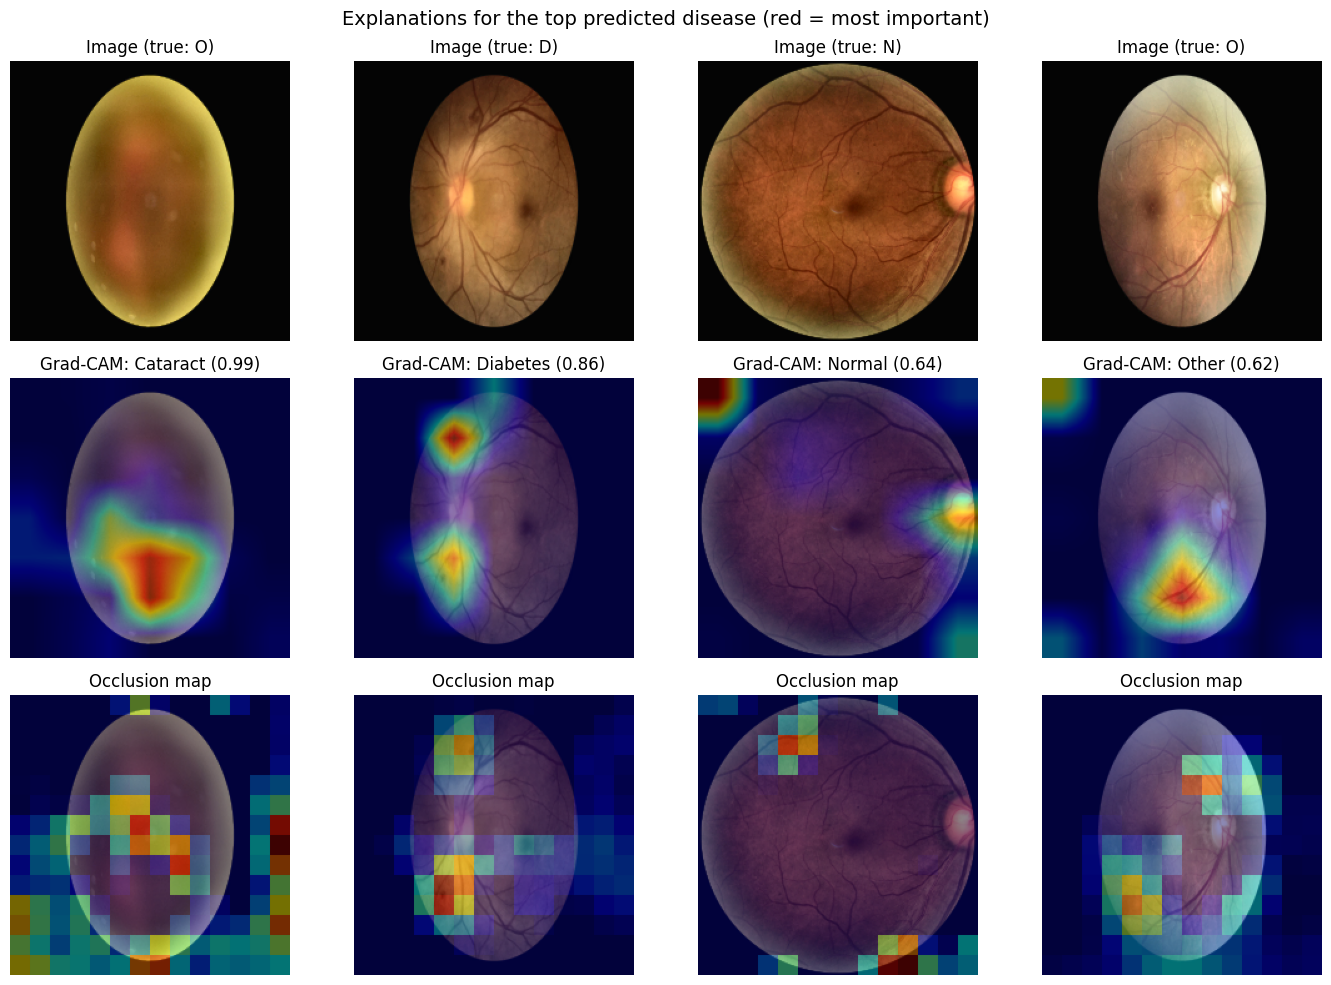

In [23]:
# Needs Steps 5-7 (X_te, Y_te) and the trained model.
model.load_state_dict(torch.load(BEST_PATH, map_location=device)); model.eval()
rng = np.random.RandomState(1)
pick = rng.choice(np.where(Y_te.sum(1) > 0)[0], 4, replace=False)
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for k, i in enumerate(pick):
    probs, c, cam, occ = explain(X_te[i])
    true = ",".join(np.array(CLASSES)[Y_te[i] > 0])
    ax[0, k].imshow(X_te[i]);                 ax[0, k].set_title(f"Image (true: {true})")
    ax[1, k].imshow(overlay(X_te[i], cam));   ax[1, k].set_title(f"Grad-CAM: {CLASS_NAMES[c]} ({probs[c]:.2f})")
    ax[2, k].imshow(overlay(X_te[i], occ));   ax[2, k].set_title("Occlusion map")
    for r in range(3): ax[r, k].axis("off")
plt.suptitle("Explanations for the top predicted disease (red = most important)", fontsize=14); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/xai_gallery.png", dpi=150); plt.show()

## Step 18 - Save inference files
Saves class names and the tuned thresholds next to the best model so the UI can load them.

In [24]:
import json
json.dump({"classes": CLASS_NAMES, "thresholds": [float(t) for t in thresholds], "img_size": S},
          open(f"{OUT_DIR}/inference_config.json", "w"))
print("Saved:", f"{OUT_DIR}/inference_config.json", "and", BEST_PATH)

Saved: /kaggle/working/results_trial2/inference_config.json and /kaggle/working/results_trial2/best_hybrid_model.pth


## Step 19 - Web UI (Gradio)
**What:** upload a fundus image -> probabilities for 8 diseases, detected diseases, Grad-CAM and occlusion maps.
**How:** the image gets the same CLAHE preprocessing, the model predicts, and the saved thresholds decide what is 'detected'. A public link is printed (Internet must be ON; it lives while the notebook runs).
**After a restart:** run Steps 1, 2, 8, 17, then 19 (needs the files from Step 18). *Research prototype, not for medical use.*

In [25]:
%pip install -q gradio
import gradio as gr, json, base64

cfg = json.load(open(f"{OUT_DIR}/inference_config.json"))
TH  = np.array(cfg["thresholds"])
model.load_state_dict(torch.load(f"{OUT_DIR}/best_hybrid_model.pth", map_location=device)); model.eval()

# ---------- eye background (inline SVG, no file needed) ----------
EYE_SVG = """<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 1200 700' preserveAspectRatio='xMidYMid slice'>
<defs>
<radialGradient id='iris' cx='50%' cy='50%' r='50%'>
<stop offset='0%' stop-color='#0b1a2b'/><stop offset='35%' stop-color='#1f6f8b'/>
<stop offset='75%' stop-color='#2fa4a9'/><stop offset='100%' stop-color='#0e3b4d'/>
</radialGradient>
<linearGradient id='bg' x1='0' y1='0' x2='1' y2='1'>
<stop offset='0%' stop-color='#06101f'/><stop offset='100%' stop-color='#0d2a3f'/>
</linearGradient>
<clipPath id='eyeclip'><path d='M120 350 Q600 20 1080 350 Q600 680 120 350 Z'/></clipPath>
</defs>
<rect width='1200' height='700' fill='url(#bg)'/>
<path d='M120 350 Q600 20 1080 350 Q600 680 120 350 Z' fill='#eaf2f6'/>
<g clip-path='url(#eyeclip)'>
<circle cx='600' cy='350' r='215' fill='url(#iris)'/>
<g stroke='#7fd6d8' stroke-opacity='0.35' stroke-width='2'>
<line x1='600' y1='350' x2='600' y2='135'/><line x1='600' y1='350' x2='815' y2='350'/>
<line x1='600' y1='350' x2='600' y2='565'/><line x1='600' y1='350' x2='385' y2='350'/>
<line x1='600' y1='350' x2='752' y2='198'/><line x1='600' y1='350' x2='752' y2='502'/>
<line x1='600' y1='350' x2='448' y2='502'/><line x1='600' y1='350' x2='448' y2='198'/>
</g>
<circle cx='600' cy='350' r='215' fill='none' stroke='#0a2a3a' stroke-width='10'/>
<circle cx='600' cy='350' r='95' fill='#020608'/>
<circle cx='650' cy='300' r='30' fill='#ffffff' fill-opacity='0.85'/>
<circle cx='560' cy='400' r='12' fill='#ffffff' fill-opacity='0.45'/>
</g>
<path d='M120 350 Q600 20 1080 350 Q600 680 120 350 Z' fill='none' stroke='#9fd8e6' stroke-width='6'/>
</svg>"""
EYE_B64 = base64.b64encode(EYE_SVG.encode()).decode()

CSS = f"""
<style>
.gradio-container {{
  background: linear-gradient(rgba(6,16,31,0.78), rgba(6,16,31,0.78)),
              url("data:image/svg+xml;base64,{EYE_B64}") center / cover no-repeat fixed !important;
}}
.gradio-container .block, .gradio-container .form, .gradio-container .panel {{
  background: rgba(255,255,255,0.90) !important;
  backdrop-filter: blur(4px);
}}
.gradio-container .block, .gradio-container .block * {{ color: #0b1a2b; }}
.gradio-container button.primary {{ color: #ffffff !important; }}
</style>
"""

def clahe_array(img_rgb):
    img = cv2.resize(np.ascontiguousarray(img_rgb, dtype=np.uint8), (S, S), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def analyse(image, disease, show_occ):
    if image is None:
        return None, "Please upload a fundus image.", None, None
    img = np.array(image)
    if img.ndim == 2: img = np.stack([img] * 3, -1)
    img = clahe_array(img[..., :3])
    c = None if disease == "Auto (top prediction)" else CLASS_NAMES.index(disease)
    probs, c, cam, occ = explain(img, c, show_occ)
    found = [n for n, p, t in zip(CLASS_NAMES, probs, TH) if p >= t]
    text = ("Detected (above tuned thresholds): " + ", ".join(found)) if found else "No disease above its threshold."
    text += f"\nExplained disease: {CLASS_NAMES[c]} (probability {probs[c]:.2f})"
    text += "\nResearch prototype - not a medical diagnosis."
    return ({n: float(p) for n, p in zip(CLASS_NAMES, probs)}, text,
            overlay(img, cam), overlay(img, occ) if show_occ else None)

with gr.Blocks(title="Retinal Multi-Disease Detection") as demo:
    gr.HTML(CSS)
    gr.Markdown("# Retinal multi-disease detection \nEfficientNet-B3 + CBAM + FPN + Swin-T. "
                "**Research prototype - not for medical use.** Works best on ODIR-style colour fundus photos.")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Fundus image")
            dis = gr.Dropdown(["Auto (top prediction)"] + CLASS_NAMES, value="Auto (top prediction)", label="Explain which disease?")
            occ_cb = gr.Checkbox(value=True, label="Also compute occlusion map (slower)")
            btn = gr.Button("Analyse", variant="primary")
        with gr.Column():
            out_lbl = gr.Label(num_top_classes=8, label="Probability per disease")
            out_txt = gr.Textbox(label="Result", lines=4)
    with gr.Row():
        out_cam = gr.Image(label="Grad-CAM (CNN branch)")
        out_occ = gr.Image(label="Occlusion map (whole model)")
    gr.Markdown("**How to read:** red/warm areas pushed the prediction for the chosen disease. "
                "Good sign: the model looks at the optic disc, macula, vessels or lesions. "
                "Bad sign: it looks at image borders or corners.")
    btn.click(analyse, [inp, dis, occ_cb], [out_lbl, out_txt, out_cam, out_occ])

demo.launch(share=True, debug=False)     # prints a public link (Internet must be ON)

Note: you may need to restart the kernel to use updated packages.
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://8bd2e6888fffecb46b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
